# nmr.solvent_transfer

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.solvent_transfer')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "nmr.solvent_transfer",
  "status": "recorded_results",
  "source_sha256": {
    "solvent_transfer_reference32_20261116.json": "7532dc2b785a93aa51323934bb748b768f1bfc7c820809bc2065d0840afc543f"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "nucleus": "1H",
    "source_ppm": 1.45,
    "source_solvent": "CD3OD",
    "target_solvent": "acetone-d6",
    "query_connectivity": "C1CCCCC1"
  },
  "output": {
    "source_ppm": 1.45,
    "predicted_target_ppm": 1.3799999999999997,
    "predicted_delta_ppm": -0.07000000000000028,
    "source_solvent": "CD3OD",
    "target_solvent": "acetone-d6",
    "nucleus": "1H",
    "query_connectivity": "C1CCCCC1",
    "reference": {
      "identity": "C1COCCO1",
      "molecule_id": "10016061",
      "atom_id": "10093018",
      "source_ppm": 3.66,
      "target_ppm": 3.59,
      "source_spectrum_ids": [
        "20197666"
      ],
      "target_spectrum_ids": [
        "20197080"
      ]
    },
    "tanimoto_similarity": 0.125,
    "same_connectivity_excluded": true,
    "method": "nearest_paired_experimental_reference_delta",
    "model_kind": "retrieval_baseline_not_neural_model",
    "query_molecule_id": "10811",
    "query_atom_id": "10046537",
    "target_reference_pp

## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | 13C | atoms | 140 |
| recorded evaluation | 13C | molecules | 13 |
| recorded evaluation | 13C | mae_ppm | 1.09429 |
| recorded evaluation | 13C | unchanged_shift_mae_ppm | 1.16371 |
| recorded evaluation | 13C | rmse_ppm | 1.90935 |
| recorded evaluation | 1H | atoms | 156 |
| recorded evaluation | 1H | molecules | 19 |
| recorded evaluation | 1H | mae_ppm | 0.137628 |
| recorded evaluation | 1H | unchanged_shift_mae_ppm | 0.135385 |
| recorded evaluation | 1H | rmse_ppm | 0.376179 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## 预测／参考对照图

参考检索基线可执行，但 H 没有优于位移不变基线。仍需溶剂条件模型及独立配对数据。

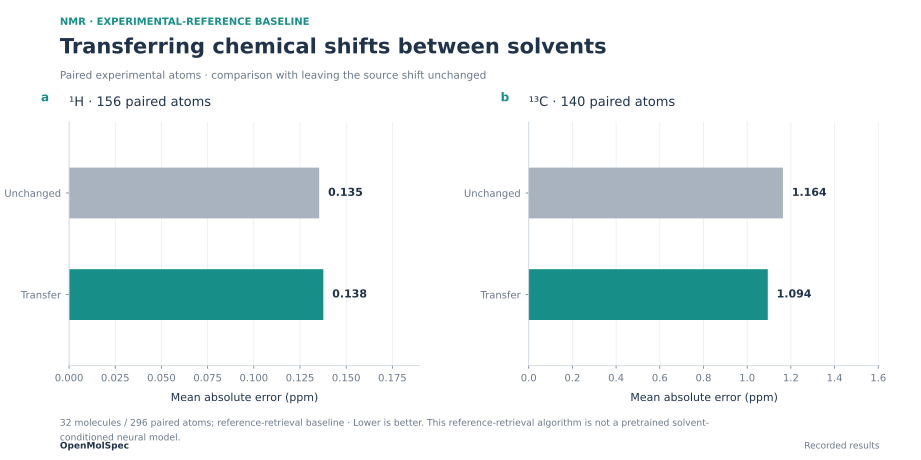

In [4]:
figure = render('nmr.solvent_transfer', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/nmr-solvent_transfer.md) · [Quick Start](../quickstart.md)
